In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from pandas import read_csv
import math
import keras
from keras.models import Sequential
from keras.layers import Dense
from keras.layers import LSTM
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error
from keras.layers import Dense, Activation, Dropout
import time #helper libraries
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from pandas import read_csv
import math
import keras
from keras.models import Sequential
from keras.layers import Dense
from keras.layers import LSTM
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error
from keras.layers import Dense, Activation, Dropout
import time #helper libraries
# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import accuracy_score
import itertools
from sklearn.metrics import accuracy_score, classification_report

import os
'''
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))
'''
# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

2025-12-13 21:11:18.383694: I tensorflow/core/util/port.cc:111] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2025-12-13 21:11:18.393432: I tensorflow/tsl/cuda/cudart_stub.cc:28] Could not find cuda drivers on your machine, GPU will not be used.
2025-12-13 21:11:18.434241: E tensorflow/compiler/xla/stream_executor/cuda/cuda_dnn.cc:9342] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2025-12-13 21:11:18.434283: E tensorflow/compiler/xla/stream_executor/cuda/cuda_fft.cc:609] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2025-12-13 21:11:18.434312: E tensorflow/compiler/xla/stream_executor/cuda/cuda_blas.cc:1518] Unable to register cuBLAS factory: Attempting to regi

"\nfor dirname, _, filenames in os.walk('/kaggle/input'):\n    for filename in filenames:\n        print(os.path.join(dirname, filename))\n"

In [2]:
df= pd.read_csv("brian_news_stocks_tesla_2023_processses_with_agg.csv")
score_cols = [f"scores_{i}" for i in range(23)]
df = df.drop(columns=score_cols)

In [3]:
df = df.sort_values(by="timestamp").reset_index(drop=True)


In [4]:
df['close_sign'] = (df['close'] > df['close'].shift(1)).astype(int)
df['close_diff'] = (df['close'].diff()).astype(float)

In [5]:
df['close_diff'] = df['close_diff'].fillna(0)


In [6]:
df.columns

Index(['timestamp', 'symbol', 'open', 'high', 'low', 'close', 'volume',
       'sma_10', 'sma_50', 'ema_20', 'rsi_14', 'macd', 'macd_signal',
       'macd_hist', 'volatility_20', 'target_up_next', 'day', 'hour',
       'sum_of_scores', 'avg_of_scores', 'normalized_avg', 'max_of_scores',
       'min_of_scores', 'normalized_min', 'normalized_max',
       'avg_score_of_normalized_min', 'avg_score_of_normalized_max',
       'avg_score_of_normalized_avg', 'close_sign', 'close_diff'],
      dtype='object')

In [7]:
df['close_sign'] 

0       0
1       1
2       0
3       0
4       1
       ..
1032    0
1033    1
1034    1
1035    0
1036    0
Name: close_sign, Length: 1037, dtype: int64

# LSTM

## Close price with avg min, and max score of all. 

In [8]:
# convert an array of values into a dataset matrix
def create_dataset(dataset, look_back=1, target_col=0):
    dataX, dataY = [], []
    for i in range(len(dataset)-look_back-1):
        a = dataset[i:(i+look_back), :]          # full feature window
        dataX.append(a)
        dataY.append(dataset[i + look_back, target_col])
    return np.array(dataX), np.array(dataY)


15 0.5


2025-12-13 21:12:10.296567: E tensorflow/compiler/xla/stream_executor/cuda/cuda_driver.cc:268] failed call to cuInit: CUDA_ERROR_NO_DEVICE: no CUDA-capable device is detected


16/16 [==============================] - 0s 2ms/step
15 0.7
10/10 [==============================] - 0s 2ms/step
30 0.5
16/16 [==============================] - 0s 2ms/step
30 0.7
9/9 [==============================] - 0s 2ms/step


/software/qanalytics/jupyterhub/env/lib/python3.11/site-packages/sklearn/metrics/_plot/confusion_matrix.py:136: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, ax = plt.subplots()


9/9 [==============================] - 0s 2ms/step
45 0.5
15/15 [==============================] - 0s 3ms/step
45 0.7
9/9 [==============================] - 0s 3ms/step
60 0.5
15/15 [==============================] - 0s 3ms/step
60 0.7
8/8 [==============================] - 0s 3ms/step
75 0.5
14/14 [==============================] - 0s 4ms/step
75 0.7
8/8 [==============================] - 0s 4ms/step
90 0.5
14/14 [==============================] - 0s 4ms/step
90 0.7
7/7 [==============================] - 0s 5ms/step
105 0.5
13/13 [==============================] - 0s 5ms/step
105 0.7
7/7 [==============================] - 0s 5ms/step
120 0.5
13/13 [==============================] - 0s 6ms/step
120 0.7
6/6 [==============================] - 0s 6ms/step
135 0.5
12/12 [==============================] - 0s 6ms/step
135 0.7
6/6 [==============================] - 0s 6ms/step


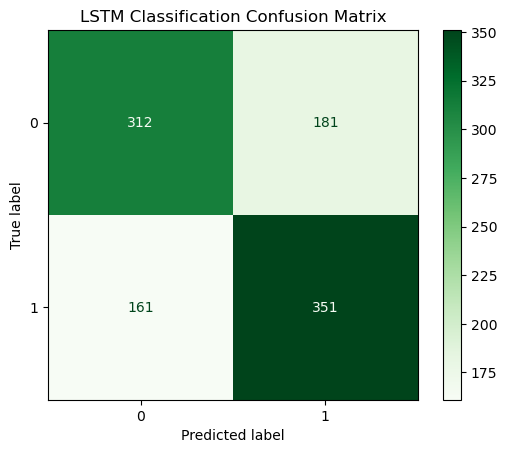

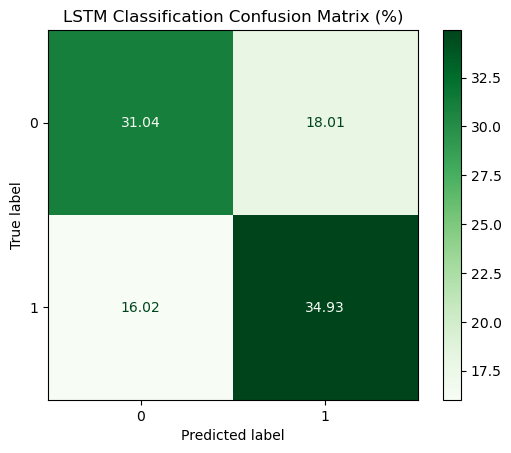

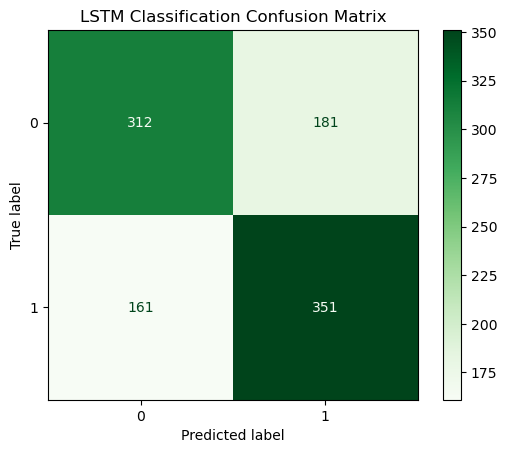

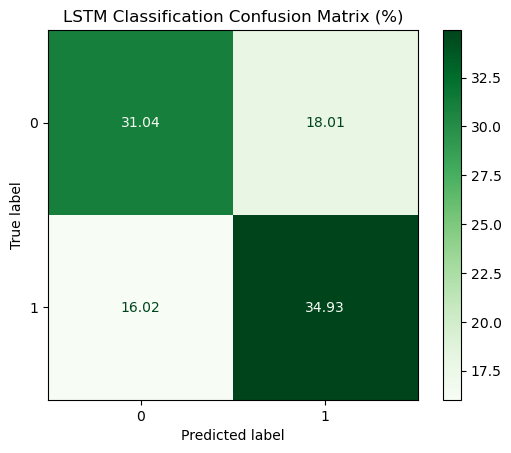

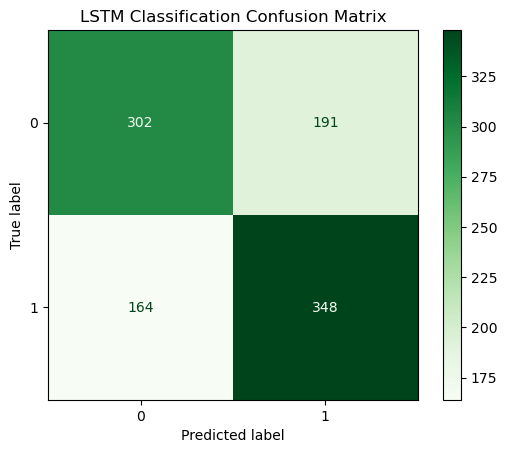

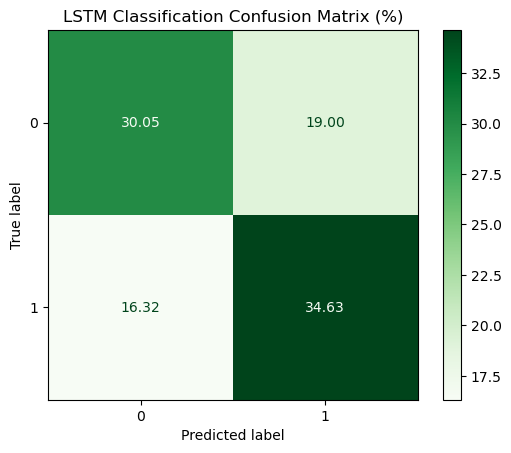

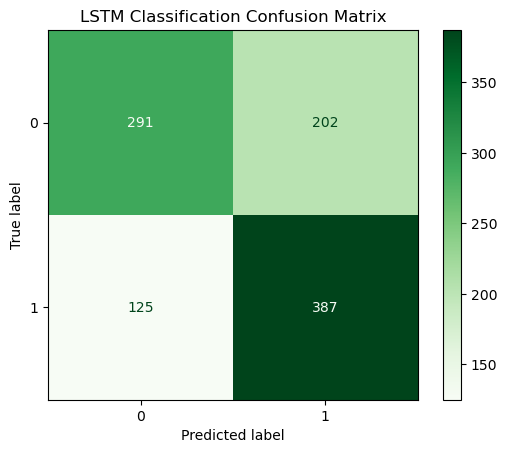

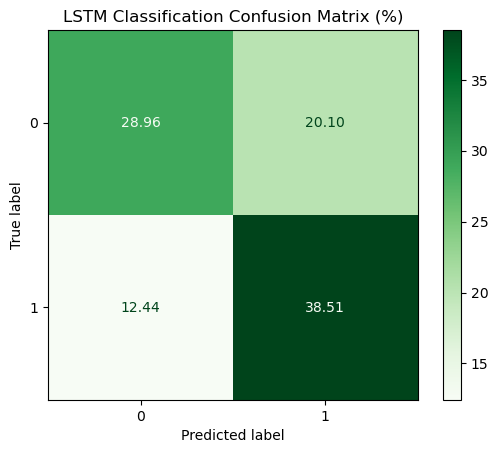

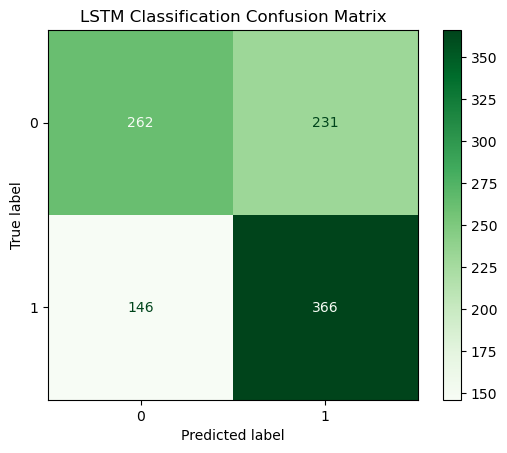

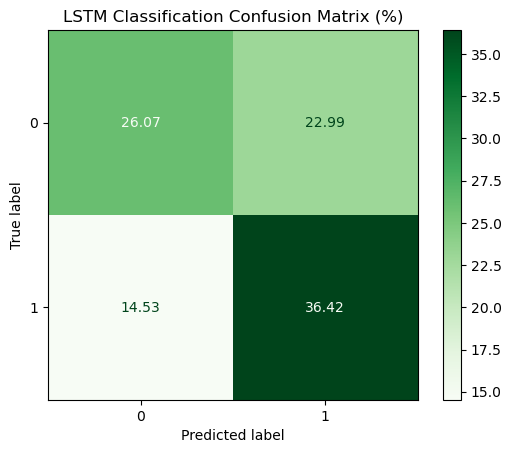

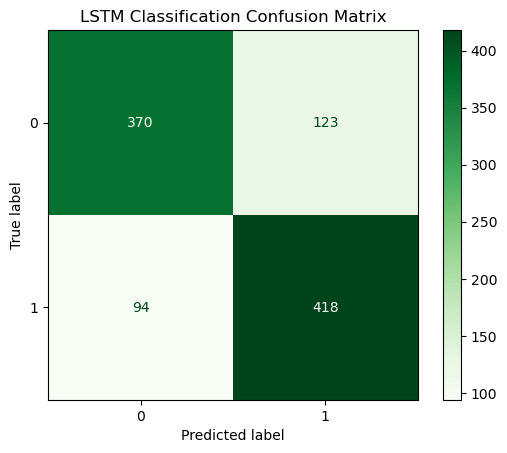

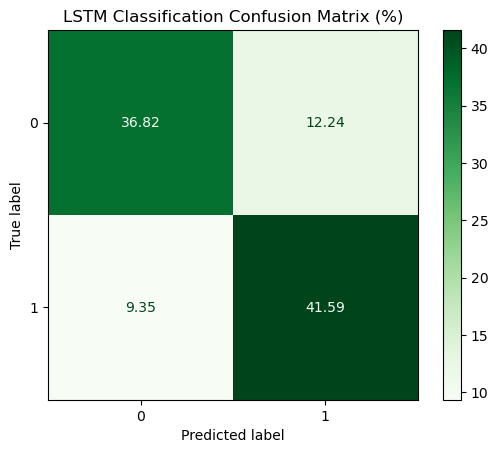

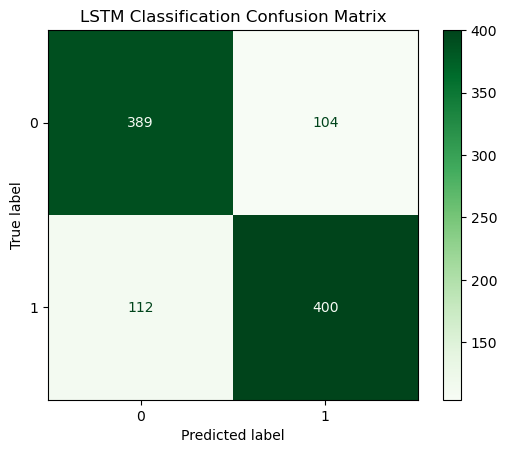

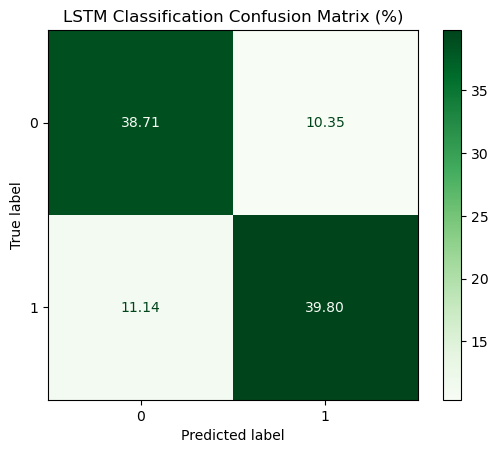

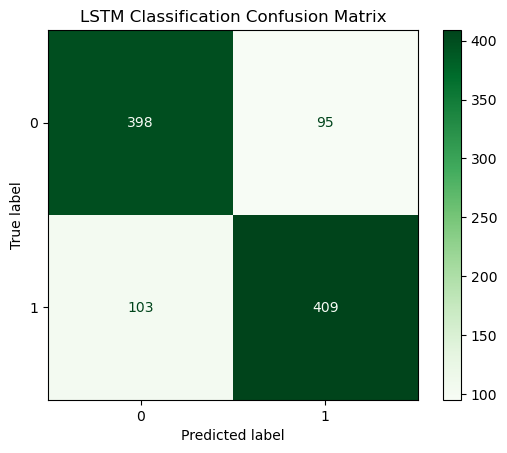

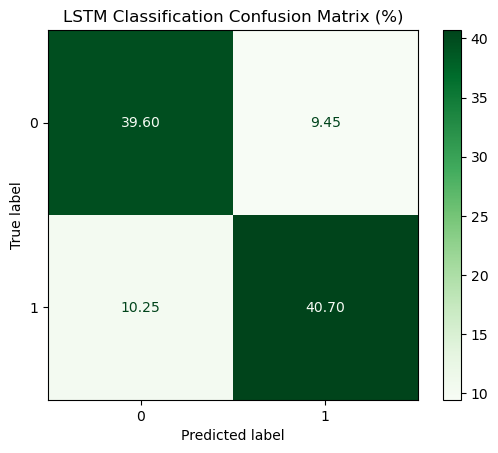

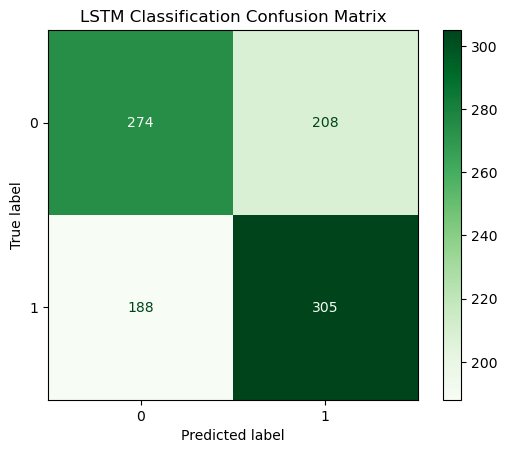

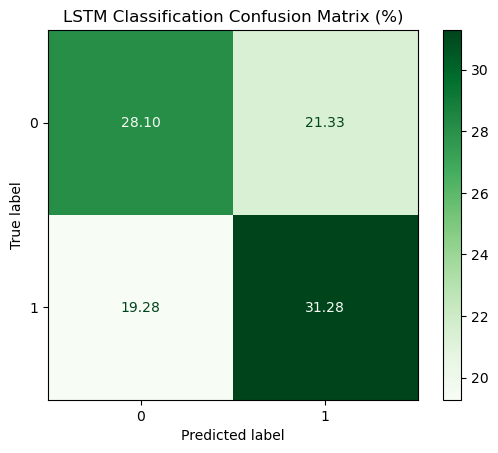

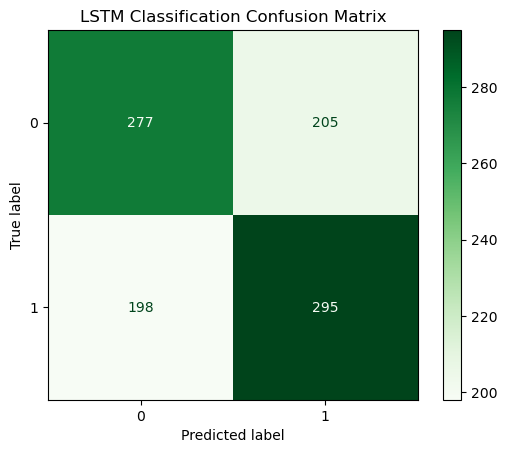

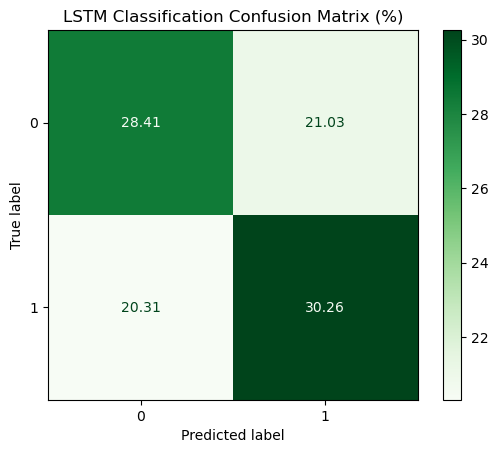

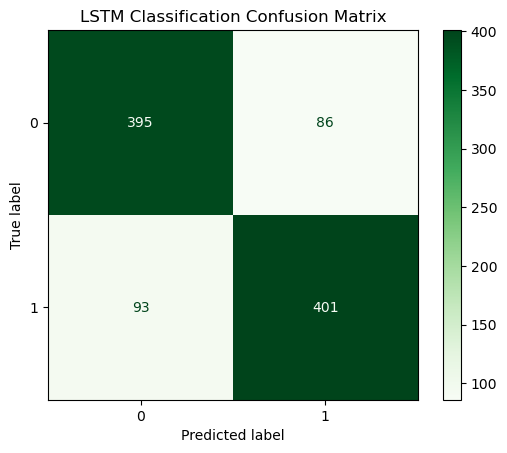

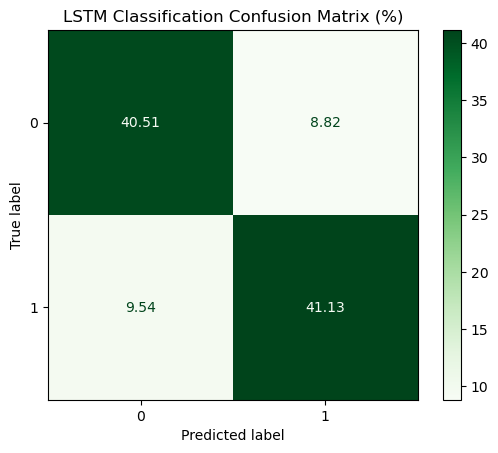

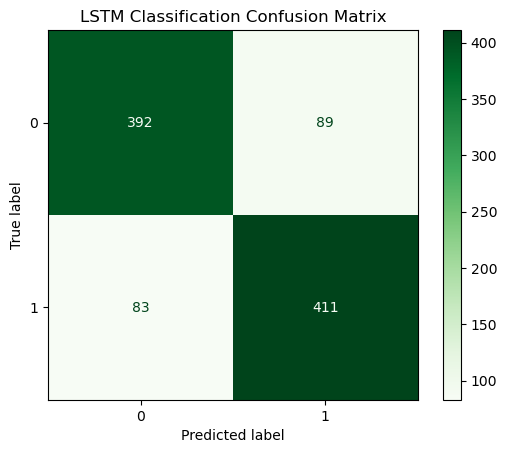

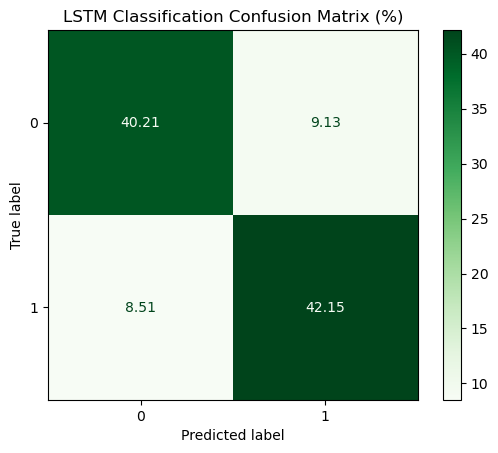

In [9]:
n_repeats = 10
lookbacks = np.arange(15, 150, 15)
train_sizes = [0.5, 0.7]
rows = []
best_acc = -float("inf")
worst_acc = float("inf")

for lookback, ts in itertools.product(lookbacks, train_sizes):
    print(lookback, ts)
    for repeat in range(n_repeats):


        # fix random seed for reproducibility
        np.random.seed(5)


        # take close price column[5]
        #all_y = df["close"].values
        dataset = df[['close_sign','avg_score_of_normalized_min', 'avg_score_of_normalized_max',
               'avg_score_of_normalized_avg']].values
        #dataset=all_y.reshape(-1, 1)
        target_col = 0 # target label is Close
        # normalize ALL features
        #scaler = MinMaxScaler(feature_range=(0, 1))
        #dataset = scaler.fit_transform(dataset)
        # split into train and test sets, 50% test data
        train_size = int(len(dataset) * ts)
        train, test = dataset[0:train_size, :], dataset[train_size:, :]
        # create supervised dataset
        look_back = lookback
        trainX, trainY = create_dataset(train, look_back, target_col)
        testX, testY = create_dataset(test, look_back, target_col)
        # reshape input to be [samples, time steps, features]
        n_features = dataset.shape[1]
        trainX = trainX.reshape(trainX.shape[0], look_back, n_features)
        testX = testX.reshape(testX.shape[0], look_back, n_features)
        # create and fit the LSTM network, optimizer=adam, 25 neurons, dropout 0.1
        model = Sequential()
        model.add(LSTM(25, input_shape=(look_back, n_features)))
        model.add(Dropout(0.1))
        model.add(Dense(1, activation='sigmoid'))
        model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])
        model.fit(trainX, trainY, epochs=1000, batch_size=240, verbose=0)
        # predictions
        trainPredict = model.predict(trainX)
        testPredict = model.predict(testX)
        # Convert continuous labels to 0/1 using the same threshold as predictions
        threshold = 0.5  # or whatever makes sense for your data
        trainY_class = (trainY > threshold).astype(int).reshape(-1)
        testY_class = (testY > threshold).astype(int).reshape(-1)

        trainPredClass = (trainPredict > threshold).astype(int).reshape(-1)
        testPredClass = (testPredict > threshold).astype(int).reshape(-1)


        #print("Train Accuracy:", accuracy_score(trainY_class, trainPredClass))
        #print("Test Accuracy:", accuracy_score(testY_class, testPredClass))
        #print("Classification Report (Test):")
        #print(classification_report(testY_class, testPredClass))


        # Combine train and test if you want overall
        y_true = np.concatenate([trainY_class, testY_class])
        y_pred = np.concatenate([trainPredClass, testPredClass])
        
        
        accuracy = accuracy_score(y_true, y_pred)

        if accuracy > best_acc:
            best_acc = accuracy
            
            cm = confusion_matrix(y_true, y_pred)
            disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[0, 1])
            disp.plot(cmap=plt.cm.Greens)
            plt.title("LSTM Classification Confusion Matrix")
            #plt.show()
            plt.savefig(f"LSTM_Model2_Classification_best_acc_lb{lookback}_ts{ts}_repeat{repeat}.png")


            # Combine train and test if you want overall
            y_true = np.concatenate([trainY_class, testY_class])
            y_pred = np.concatenate([trainPredClass, testPredClass])

            # Compute confusion matrix
            cm = confusion_matrix(y_true, y_pred)

            # Convert to percentages
            cm_percent = cm.astype('float') / cm.sum() * 100

            # Display
            disp = ConfusionMatrixDisplay(confusion_matrix=cm_percent, display_labels=[0, 1])
            disp.plot(cmap=plt.cm.Greens, values_format=".2f")  # format as 2 decimal percentages
            plt.title("LSTM Classification Confusion Matrix (%)")
            #plt.show()
            plt.savefig(f"LSTM_Model2_Classification_best_acc_lb{lookback}_ts{ts}_repeat{repeat}.png")

            #print(f"Total Accuracy: {accuracy*100:.2f}%")
        if accuracy < worst_acc:
            worst_acc = accuracy
            
            cm = confusion_matrix(y_true, y_pred)
            disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[0, 1])
            disp.plot(cmap=plt.cm.Greens)
            plt.title("LSTM Classification Confusion Matrix")
            #plt.show()
            plt.savefig(f"LSTM_Model2_Classification_best_acc_lb{lookback}_ts{ts}_repeat{repeat}.png")


            # Combine train and test if you want overall
            y_true = np.concatenate([trainY_class, testY_class])
            y_pred = np.concatenate([trainPredClass, testPredClass])

            # Compute confusion matrix
            cm = confusion_matrix(y_true, y_pred)

            # Convert to percentages
            cm_percent = cm.astype('float') / cm.sum() * 100

            # Display
            disp = ConfusionMatrixDisplay(confusion_matrix=cm_percent, display_labels=[0, 1])
            disp.plot(cmap=plt.cm.Greens, values_format=".2f")  # format as 2 decimal percentages
            plt.title("LSTM Classification Confusion Matrix (%)")
            #plt.show()
            plt.savefig(f"LSTM_Model2_Classification_worst_acc_lb{lookback}_ts{ts}_repeat{repeat}.png")
        
        
        result = {"n_repeat": repeat,"lookback": look_back,"test_size": 1-ts, "test_acc":accuracy}
        rows.append(result)

df_results= pd.DataFrame(rows)

In [11]:
df_results.to_csv("LSTM_Model2_Classification__simulation.csv", index=False)